# 14 — Yellowstone visitation: interventions (Q1, Q3), climate (Q2), North gate (Q5)

Reuses the Q0 noise model from notebook 13 (`reports/tables/q0_sarima_spec.json`).

Inputs from other parts are kept as copies inside this folder so Part 3 runs on its own:
`data/processed/monthly_temperature.csv` and `data/processed/winter_severity_index.csv` (built in
Part 2 from three SNOTEL stations) and `data/raw/yellowstone_wolves_1995_2025.csv` (Part 1).

| Q | question | main method |
|---|---|---|
| 1 | Did wolves bring tourists? | intervention at 1995 on winter visits, summer control, North-gate dose–response |
| 2 | Is a warmer climate shifting when people visit? | shoulder share + centroid trends (Mann–Kendall, Sen), temperature regression |
| 3 | How fast does tourism recover from shocks? | SARIMA counterfactuals, ω/(1−δB) decay models |
| 5 | Does North/Northeast winter traffic grow faster? | difference series vs Highway 191, break test |

**Two data facts that shape Q1 and Q5** (from the IRMA reports, see notebook 13 / data notes):
1. NPS switched from manual counts to traffic-counter estimates in **1993** — two years before
   wolves. Any 1995 comparison needs a 1993 control.
2. The entrance traffic file counts **wheeled vehicles only** and starts in **1993**. In winter
   only the North gate has cars (West/South/East are snowmobile-only, NE is unstaffed), so the
   brief's North/NE-vs-West comparison is replaced by North vs Highway 191 (US-191 through the
   park's west edge, a regional-traffic control).

In [1]:
import json, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
import ruptures as rpt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.api import VAR
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

v = pd.read_csv(ROOT / "data/processed/yell_visits_monthly.csv", parse_dates=["Date"], index_col="Date")
v = v[v.Preliminary == 0].asfreq("MS")
y = v["LogVisits"]
spec = json.loads((TAB / "q0_sarima_spec.json").read_text())
ORDER, SORDER = tuple(spec["order"]), tuple(spec["seasonal_order"])
X0 = v[["D_fire88", "D_covid20", "D_flood22", "D_shutdown"]].copy()
X0["C_count93"] = (v.index >= "1993-01-01").astype(int)
X0["C_count13"] = (v.index >= "2013-01-01").astype(int)
assert list(X0.columns) == spec["exog"]
print("Q0 model:", ORDER, SORDER)

sev = pd.read_csv(ROOT / "data/processed/winter_severity_index.csv").set_index("Year").Severity_index
wolves = pd.read_csv(ROOT / "data/raw/yellowstone_wolves_1995_2025.csv").set_index("year")
temp = pd.read_csv(ROOT / "data/processed/monthly_temperature.csv", parse_dates=["Month"]).rename(columns={"Month": "Date"})
traffic = pd.read_csv(ROOT / "data/processed/yell_traffic_by_entrance.csv", parse_dates=["Date"])

def pct(b):  # log coefficient -> % change
    return 100 * (np.exp(b) - 1)

Q0 model: (0, 1, 2) (1, 1, 1, 12)


---
# Q1 — Did wolves bring tourists?

Wolves were released in Lamar Valley in Jan–Mar 1995 (14) and 1996 (17). The winter of
1995–96 is the first with free-roaming wolves.

**Winter series.** Visits Dec–Mar, labelled by the Jan–Mar year (winter "1996" = Dec 1995–Mar 1996).
1980–2025 → 46 winters. Summer control: Jun–Aug of the same year.

**Regressors**
* `step95` = 1 from winter 1996 on (first winter after release; the Jan–Mar 1995 winter had
  wolves still in acclimation pens)
* `count93` = 1 from 1993 (counting-method change)
* `snow04` = 1 from winter 2004 (snowmobile limits, best-available-technology rules)
* `severity` = winter severity index (repo, 3 SNOTEL stations)
* `shut96` = winter 1996, which contains the Dec 1995–Jan 1996 shutdown

Noise model: annual data cannot carry a seasonal SARIMA, so N_t is ARIMA(1,0,0) with a linear
trend (AIC-best of AR(0–2) and ARIMA(0,1,1), checked below). The monthly version further down
uses the full Q0 SARIMA.

In [2]:
def winter_sum(df, col="Visits"):
    w = df[df.index.month.isin([12, 1, 2, 3])].copy()
    w["S"] = w.index.year + (w.index.month == 12)
    return w.groupby("S")[col].sum()

W = winter_sum(v).loc[1980:2025]
Su = v[v.index.month.isin([6, 7, 8])].groupby(v[v.index.month.isin([6, 7, 8])].index.year).Visits.sum().loc[1980:2025]
q1 = pd.DataFrame({"winter": W, "summer": Su})
q1["lw"], q1["ls"] = np.log(q1.winter), np.log(q1.summer)
q1["diff"] = q1.lw - q1.ls
yr = q1.index.values
q1["step95"] = (yr >= 1996).astype(int)
q1["ramp95"] = np.clip((yr - 1995) / 5, 0, 1)    # 0 up to 1995, linear to 1 by 2000
q1["count93"] = (yr >= 1993).astype(int)
q1["snow04"] = (yr >= 2004).astype(int)
q1["severity"] = sev.reindex(yr).values
q1["shut96"] = (yr == 1996).astype(int)
q1["flood22"] = (yr == 2022).astype(int)          # summer control only
q1["covid20"] = (yr == 2020).astype(int)          # summer control only (Jun 2020 still reduced)
q1.round(3).to_csv(TAB / "q1_winter_summer_annual.csv")
q1.head()

,winter,summer,lw,ls,diff,step95,ramp95,count93,snow04,severity,shut96,flood22,covid20
1980,111926.0,1406570.0,11.625593,14.156665,-2.531071,0,0.0,0,0,0.157,0,0,0
1981,94413.0,1775552.0,11.455434,14.389622,-2.934188,0,0.0,0,0,-0.989,0,0,0
1982,104915.0,1727947.0,11.560906,14.362445,-2.801539,0,0.0,0,0,1.278,0,0,0
1983,71563.0,1705882.0,11.178333,14.349593,-3.171259,0,0.0,0,0,0.404,0,0,0
1984,70385.0,1633775.0,11.161735,14.306404,-3.144668,0,0.0,0,0,-0.157,0,0,0


### Figure: winter vs summer, with the 1995 line

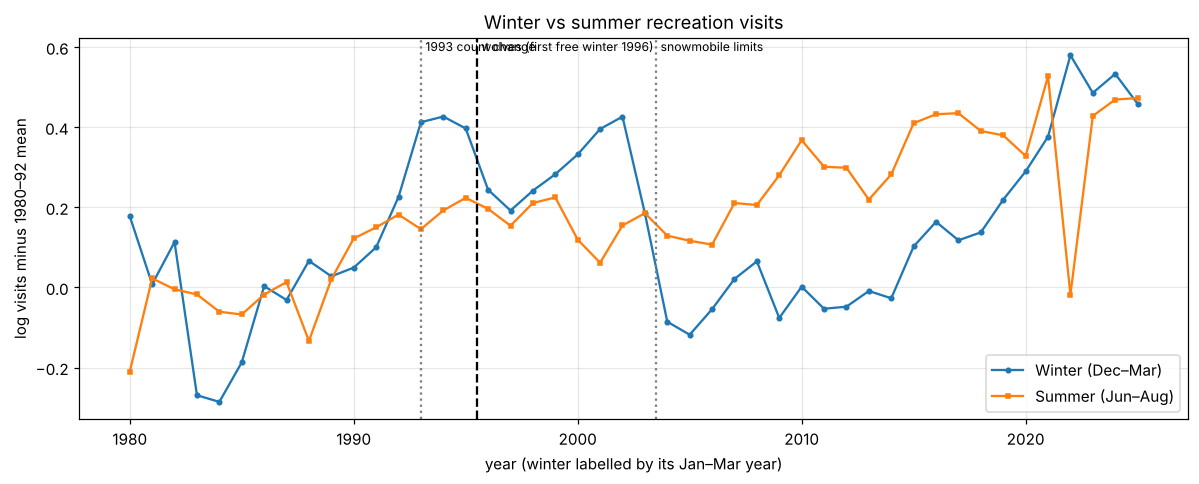

In [3]:
base = q1.loc[1980:1992]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(q1.index, q1.lw - base.lw.mean(), "o-", ms=3, label="Winter (Dec–Mar)")
ax.plot(q1.index, q1.ls - base.ls.mean(), "s-", ms=3, label="Summer (Jun–Aug)")
for x, lab, sty in [(1993, "1993 count change", ":"), (1995.5, "wolves (first free winter 1996)", "--"),
                    (2003.5, "snowmobile limits", ":")]:
    ax.axvline(x, color="k" if sty == "--" else "gray", ls=sty)
    ax.text(x + 0.2, 0.62, lab, fontsize=8, va="top")
ax.set_ylabel("log visits minus 1980–92 mean"); ax.set_xlabel("year (winter labelled by its Jan–Mar year)")
ax.set_title("Winter vs summer recreation visits"); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "q1_winter_vs_summer_1995.png", dpi=150); plt.show()

### Noise-model check for the annual winter series

In [4]:
FULL_W = ["step95", "count93", "snow04", "severity", "shut96"]
rows = []
for o in [(0, 0, 0), (1, 0, 0), (2, 0, 0), (0, 1, 1)]:
    m = ARIMA(q1.lw, exog=q1[FULL_W], order=o, trend="ct" if o[1] == 0 else "t").fit()
    rows.append(dict(order=str(o), AIC=m.aic, step95=m.params.step95, p=m.pvalues.step95))
pd.DataFrame(rows).round(3)

,order,AIC,step95,p
0,"(0, 0, 0)",-57.749,-0.277,0.389
1,"(1, 0, 0)",-68.133,-0.251,0.696
2,"(2, 0, 0)",-66.357,-0.246,0.537
3,"(0, 1, 1)",-62.895,-0.227,1.000


### Step and ramp models

In [5]:
def fit_int(ycol, X, sub=None, order=(1, 0, 0), trend="ct", key=None):
    d = q1 if sub is None else q1.loc[sub[0]:sub[1]]
    X = [x for x in X if d[x].nunique() > 1]
    m = ARIMA(d[ycol], exog=d[X], order=order, trend=trend).fit()
    k = key or X[0]
    b, se = m.params[k], m.bse[k]
    return dict(effect=k, omega=b, se=se, p=m.pvalues[k], **{"% effect": pct(b), "95% CI low %": pct(b - 1.96 * se),
                "95% CI high %": pct(b + 1.96 * se)}, n=int(m.nobs), AIC=m.aic,
                controls=", ".join(x for x in X if x != k)), m

specs = [
    ("Winter, step only",                    "lw",   ["step95"], None),
    ("Winter, step + 1993 count change",     "lw",   ["step95", "count93"], None),
    ("Winter, full controls",                "lw",   FULL_W, None),
    ("Winter, full controls, ramp 1995–2000", "lw",  ["ramp95", "count93", "snow04", "severity", "shut96"], None),
    ("Winter, ends 2002 (pre-snowmobile rules)", "lw", ["step95", "count93", "severity", "shut96"], (1980, 2002)),
    ("Summer control, full controls",        "ls",   ["step95", "count93", "snow04", "covid20", "flood22"], None),
    ("Winter − summer, full controls",       "diff", ["step95", "count93", "snow04", "severity", "shut96", "covid20", "flood22"], None),
]
res, models = [], {}
for name, ycol, X, sub in specs:
    r, m = fit_int(ycol, X, sub)
    res.append(dict(model=name, **r)); models[name] = m
q1_tab = pd.DataFrame(res).set_index("model")
q1_tab.round(3).to_csv(TAB / "q1_wolf_effect.csv")
q1_tab[["effect", "omega", "se", "p", "% effect", "95% CI low %", "95% CI high %", "n"]].round(3)

,effect,omega,se,p,% effect,95% CI low %,95% CI high %,n
model,,,,,,,,
"Winter, step only",step95,-0.163,0.268,0.543,-15.045,-49.787,43.737,46
"Winter, step + 1993 count change",step95,-0.177,0.295,0.550,-16.183,-52.998,49.466,46
"Winter, full controls",step95,-0.251,0.642,0.696,-22.212,-77.911,173.936,46
"Winter, full controls, ramp 1995–2000",ramp95,-0.255,0.322,0.429,-22.477,-58.763,45.740,46
"Winter, ends 2002 (pre-snowmobile rules)",step95,-0.186,0.263,0.481,-16.933,-50.431,39.201,23
"Summer control, full controls",step95,-0.087,0.075,0.246,-8.298,-20.772,6.139,46
"Winter − summer, full controls",step95,-0.150,0.300,0.617,-13.925,-52.203,55.010,46


In [6]:
print(models["Winter, full controls"].summary())

                               SARIMAX Results                                
Dep. Variable:                     lw   No. Observations:                   46
Model:                 ARIMA(1, 0, 0)   Log Likelihood                  43.066
Date:                Fri, 20 Nov 2026   AIC                            -68.133
Time:                        11:37:27   BIC                            -51.675
Sample:                             0   HQIC                           -61.968
                                 - 46                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.3401      0.056    203.296      0.000      11.231      11.449
drift          0.0204      0.008      2.592      0.010       0.005       0.036
step95        -0.2512      0.642     -0.391      0.6

### Monthly version (full Q0 SARIMA)
Same question on the monthly series: the Q0 SARIMA plus a 1995 step that is allowed to differ
between winter months (Dec–Mar) and summer months (Jun–Aug), with the 1993 count change and
the 2004 snowmobile rules also allowed to act on winter months separately. Winter severity
(index for that winter, applied to its Dec–Mar months) is added in a second version: the two
most severe winters since the 1970s are 1996 and 1997, right after the release.

In [7]:
win_m = v.index.month.isin([12, 1, 2, 3]).astype(int)
sum_m = v.index.month.isin([6, 7, 8]).astype(int)
season_yr = v.index.year + (v.index.month == 12)
Xm = X0.copy()
Xm["step95_winter"] = ((season_yr >= 1996) * win_m).astype(int)
Xm["step95_summer"] = ((v.index.year >= 1996) * sum_m).astype(int)
Xm["count93_winter"] = ((season_yr >= 1993) * win_m).astype(int)
Xm["snow04_winter"] = ((season_yr >= 2004) * win_m).astype(int)
KEYS = ["step95_winter", "step95_summer", "count93_winter", "snow04_winter", "severity_winter"]
mons = []
for lab, Xuse in [("without severity", Xm),
                  ("with winter severity", Xm.assign(severity_winter=sev.reindex(season_yr).fillna(0).values * win_m))]:
    mm = SARIMAX(y, exog=Xuse, order=ORDER, seasonal_order=SORDER).fit(disp=False)
    k = [x for x in KEYS if x in mm.params.index]
    mons.append(pd.DataFrame({"version": lab, "coef": mm.params[k], "se": mm.bse[k], "p": mm.pvalues[k]}))
mon = pd.concat(mons)
mon["% effect"] = pct(mon.coef)
mon["95% CI low %"], mon["95% CI high %"] = pct(mon.coef - 1.96 * mon.se), pct(mon.coef + 1.96 * mon.se)
mon.round(3).to_csv(TAB / "q1_monthly_sarima_effects.csv"); mon.round(3)

,version,coef,se,p,% effect,95% CI low %,95% CI high %
step95_winter,without severity,-0.189,0.094,0.044,-17.183,-31.078,-0.488
step95_summer,without severity,-0.052,0.254,0.839,-5.023,-42.237,56.166
count93_winter,without severity,0.273,0.160,0.089,31.354,-4.052,79.827
snow04_winter,without severity,-0.352,0.136,0.010,-29.646,-46.091,-8.184
step95_winter,with winter severity,-0.190,0.104,0.068,-17.290,-32.569,1.451
step95_summer,with winter severity,-0.052,0.255,0.839,-5.059,-42.412,56.523
count93_winter,with winter severity,0.274,0.160,0.087,31.551,-3.923,80.123
snow04_winter,with winter severity,-0.351,0.138,0.011,-29.636,-46.316,-7.774
severity_winter,with winter severity,-0.002,0.030,0.958,-0.161,-5.938,5.972


In [8]:
mw_sev = mon[(mon.version == "with winter severity")].loc["step95_winter"]
mw_nosev = mon[(mon.version == "without severity")].loc["step95_winter"]
print(f"Monthly winter step: {mw_nosev['% effect']:+.1f}% (p={mw_nosev.p:.3f}) without severity, "
      f"{mw_sev['% effect']:+.1f}% (p={mw_sev.p:.3f}) with severity")

Monthly winter step: -17.2% (p=0.044) without severity, -17.3% (p=0.068) with severity


### How big an effect could we have missed?
The annual full-control model is imprecise (the 1993 and 1996 steps are only three winters
apart, so they are hard to separate). The monthly model with severity is the tightest test;
its upper 95% bound is the largest wolf effect on winter visits consistent with the data.

In [9]:
up = mw_sev["95% CI high %"]
w90s = q1.loc[1993:1995, "winter"].mean()
print(f"Monthly model with severity: winter step {mw_sev['% effect']:+.1f}% "
      f"(95% CI {mw_sev['95% CI low %']:+.1f}% to {up:+.1f}%)")
print(f"Largest effect consistent with the data: {up:+.1f}% of ~{w90s:,.0f} winter visits "
      f"= {w90s * up / 100:+,.0f} visits per winter")

Monthly model with severity: winter step -17.3% (95% CI -32.6% to +1.5%)
Largest effect consistent with the data: +1.5% of ~141,445 winter visits = +2,053 visits per winter


### Stronger test: North-gate winter cars vs the number of wolves
Park-wide winter visits are dominated by snowmobile/snowcoach traffic from the West and South
to Old Faithful. Cars through the **North gate** in winter go almost entirely to Mammoth and
Lamar Valley — wolf country. If wolves draw visitors, North-gate winter traffic should rise
and fall with the wolf population, not just step up once.

* Winter = Dec–Mar, labelled by the Jan–Mar year; 1994–2021 (1993 lacks Dec 1992; a new
  North counter from June 2021 captures all lanes — the old one counted one lane — so
  2022+ is not comparable).
* Wolves = park total at the end of the previous year (wolves present that winter).
* Control: Highway 191 winter traffic (regional economy/recession, e.g. 2009–10).
* Placebo: the same regression for **summer park visits** should show no wolf effect.

In [10]:
tw = traffic[traffic.Date.dt.month.isin([12, 1, 2, 3])].copy()
tw["S"] = tw.Year + (tw.Month == 12)
TW = tw.pivot_table(index="S", columns="Entrance", values="Vehicles", aggfunc="sum").loc[1994:2025]
wv = wolves.total_wolves_end_of_year.copy(); wv.index += 1            # end of year t-1 -> winter t
nd = pd.DataFrame({"north": TW.North, "hwy191": TW["Highway 191"], "wolves": wv.reindex(TW.index)})
nd["ln"], nd["lh"], nd["lwolf"] = np.log(nd.north), np.log(nd.hwy191), np.log(nd.wolves)
nd["t"] = nd.index - 2000
dose = nd.loc[1997:2021].dropna()

drows = []
for name, X in [("wolves only", ["lwolf"]), ("+ Hwy 191 control", ["lwolf", "lh"]),
                ("+ Hwy 191 + trend", ["lwolf", "lh", "t"])]:
    a = ARIMA(dose.ln, exog=dose[X], order=(1, 0, 0), trend="c").fit()
    o = sm.OLS(dose.ln, sm.add_constant(dose[X])).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
    drows.append(dict(model=name, elasticity_AR1=a.params.lwolf, p_AR1=a.pvalues.lwolf,
                      elasticity_OLS_HAC=o.params.lwolf, p_OLS_HAC=o.pvalues.lwolf, R2_OLS=o.rsquared))
lsum = np.log(Su)                                       # placebo: summer visits in year t-1 vs wolves end of t-1
plac = pd.DataFrame({"ls": lsum.reindex(dose.index - 1).values, "lwolf": dose.lwolf.values,
                     "t": dose.t.values}, index=dose.index)
o = sm.OLS(plac.ls, sm.add_constant(plac[["lwolf", "t"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
drows.append(dict(model="PLACEBO: summer park visits", elasticity_AR1=np.nan, p_AR1=np.nan,
                  elasticity_OLS_HAC=o.params.lwolf, p_OLS_HAC=o.pvalues.lwolf, R2_OLS=o.rsquared))
dose_tab = pd.DataFrame(drows).set_index("model")
dose_tab.round(3).to_csv(TAB / "q1_north_gate_dose_response.csv"); dose_tab.round(3)

,elasticity_AR1,p_AR1,elasticity_OLS_HAC,p_OLS_HAC,R2_OLS
model,,,,,
wolves only,0.310,0.048,0.271,0.113,0.132
+ Hwy 191 control,0.301,0.090,0.319,0.122,0.222
+ Hwy 191 + trend,0.302,0.268,0.304,0.018,0.407
PLACEBO: summer park visits,NaN,NaN,-0.126,0.000,0.719


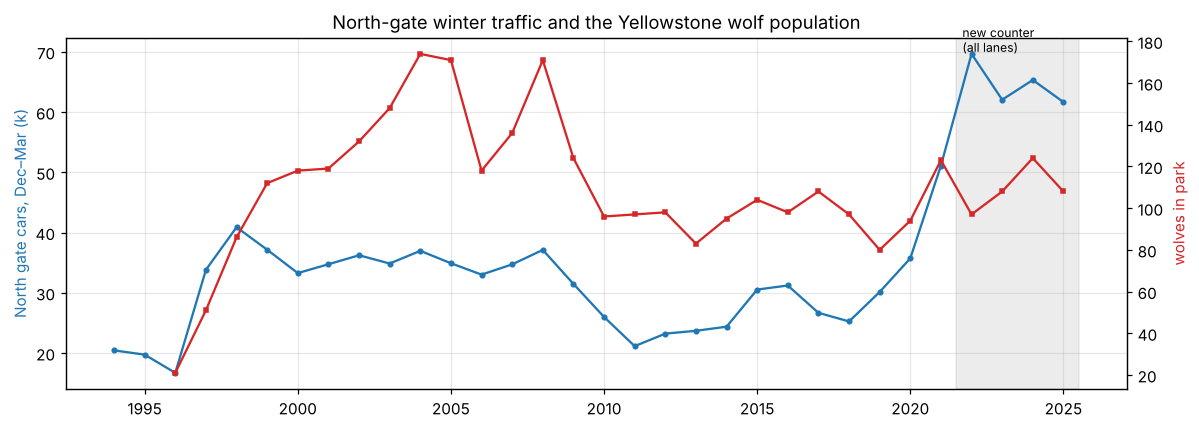

In [11]:
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(nd.index, nd.north / 1e3, "o-", ms=3, color="C0", label="North gate winter cars (k)")
ax1.set_ylabel("North gate cars, Dec–Mar (k)", color="C0")
ax2 = ax1.twinx(); ax2.plot(nd.index, nd.wolves, "s-", ms=3, color="C3", label="wolves (end of previous year)")
ax2.set_ylabel("wolves in park", color="C3"); ax2.grid(False)
ax1.axvspan(2021.5, 2025.5, color="gray", alpha=0.15); ax1.text(2021.7, 70, "new counter\n(all lanes)", fontsize=8)
ax1.set_title("North-gate winter traffic and the Yellowstone wolf population")
fig.tight_layout(); fig.savefig(FIG / "q1_north_gate_vs_wolves.png", dpi=150); plt.show()

### Q1 answer (for the final report)

In [12]:
fr, sm_, df_, mw, rp = (q1_tab.loc[k] for k in ["Winter, full controls", "Summer control, full controls",
                                                "Winter − summer, full controls", "Winter, ends 2002 (pre-snowmobile rules)",
                                                "Winter, full controls, ramp 1995–2000"])
st = q1_tab.loc["Winter, step only"]
pmin, pmax = dose_tab.iloc[:3][["p_AR1", "p_OLS_HAC"]].min().min(), dose_tab.iloc[:3][["p_AR1", "p_OLS_HAC"]].max().max()
el = dose_tab.iloc[:3][["elasticity_AR1", "elasticity_OLS_HAC"]]
q1_text = f"""Did wolves bring tourists? Not in a way that shows up in park-wide visitor counts. Winter visits
(Dec–Mar), which the brief proposed as a proxy for wolf watching, did not rise after wolves were
released. A step at the first wolf winter (1995–96) is {st['% effect']:+.0f}% (95% CI {st['95% CI low %']:+.0f}% to
{st['95% CI high %']:+.0f}%, p = {st['p']:.2f}); adding controls for NPS's 1993 switch to traffic-counter
estimates, the 2004 snowmobile rules and winter severity, a gradual 1995–2000 ramp, a sample
ending in 2002, or modelling winter minus summer all give negative, non-significant estimates
(between {q1_tab.loc[q1_tab.index.str.startswith('Winter'), '% effect'].min():.0f}% and {q1_tab.loc[q1_tab.index.str.startswith('Winter'), '% effect'].max():.0f}%, all p > {q1_tab.loc[q1_tab.index.str.startswith('Winter'), 'p'].min():.2f}).
The monthly SARIMA, which uses all 564 months and is the most precise test, points the same
way: winter months after 1996 are {abs(mw_nosev['% effect']):.0f}% below the pre-wolf pattern (p = {mw_nosev.p:.2f}), or
{abs(mw_sev['% effect']):.0f}% below (p = {mw_sev.p:.2f}) with winter severity added. Its 95% interval ({mw_sev['95% CI low %']:+.0f}% to
{mw_sev['95% CI high %']:+.1f}%) rules out a park-wide winter increase of more than about {mw_sev['95% CI high %']:.1f}%; the
annual models are much less precise. Summer visits, the control, show no change either
({sm_['% effect']:+.0f}%, p = {sm_['p']:.2f}). The likely reason is that park-wide winter visits are dominated by
snowmobile and snowcoach trips from West Yellowstone to Old Faithful, far from wolf country;
their ups and downs follow snowmobile rules (−{-mon.loc['snow04_winter'].iloc[-1:]['% effect'].iloc[0]:.0f}% after 2004) and snow, not wolves, and
the early-1990s rise coincides with the 1993 counting change.
A narrower measure points the other way. Winter cars through the North gate, the only road
open in winter and the route into Lamar Valley, doubled between the 1995–96 and 1996–97
winters and since then have moved with the size of the wolf population: an elasticity of
about {el.values.mean():.1f} (10% more wolves, about {10 * el.values.mean():.0f}% more winter cars), with p-values from
{pmin:.2f} to {pmax:.2f} depending on the model. That link is suggestive, not proven: a placebo
regression of summer visits on wolf numbers also comes out 'significant', a reminder of how
easily two trending yearly series correlate. Duffield, Neher & Patterson (2006) estimated that
wolf-related visitor spending is worth about $35.5M a year to nearby towns. Their figure measures
spending by visitors who came partly to see wolves, not extra visits to the park, so it is not
contradicted by our result: wolf watchers who would have visited anyway, or who come in
summer, add spending without adding to winter counts, and any extra winter trips would be
concentrated on the northern range, a small part of winter visits, which is where the
North-gate data hint at an effect."""
print(q1_text)
(TAB / "q1_answer_paragraph.txt").write_text(q1_text)

Did wolves bring tourists? Not in a way that shows up in park-wide visitor counts. Winter visits
(Dec–Mar), which the brief proposed as a proxy for wolf watching, did not rise after wolves were
released. A step at the first wolf winter (1995–96) is -15% (95% CI -50% to
+44%, p = 0.54); adding controls for NPS's 1993 switch to traffic-counter
estimates, the 2004 snowmobile rules and winter severity, a gradual 1995–2000 ramp, a sample
ending in 2002, or modelling winter minus summer all give negative, non-significant estimates
(between -22% and -14%, all p > 0.43).
The monthly SARIMA, which uses all 564 months and is the most precise test, points the same
way: winter months after 1996 are 17% below the pre-wolf pattern (p = 0.04), or
17% below (p = 0.07) with winter severity added. Its 95% interval (-33% to
+1.5%) rules out a park-wide winter increase of more than about 1.5%; the
annual models are much less precise. Summer visits, the control, show no change either
(-8%, p = 0.25). The l

2410

---
# Q2 — Is a warmer climate shifting when people visit?

* **Shoulder share** = visits in Apr, May, Sep, Oct ÷ yearly total.
* **Visit centroid** = visit-weighted average month (1 = Jan … 12 = Dec).
* Trend tests: Mann–Kendall + Sen's slope, 1979–2025 and 1979–2019 (pre-COVID).
* Regression: log visits on monthly mean temperature + 12 month dummies + linear trend +
  count-change steps + shock dummies, HAC (Newey–West, 12 lags) standard errors, 1984–2025.
  Temperature is missing for Mar 1984 and Feb 1994; those months drop out.

In [13]:
vv = v.copy(); vv["Year"], vv["Month"] = vv.index.year, vv.index.month
ann = vv.groupby("Year").Visits.sum()
shoulder = vv[vv.Month.isin([4, 5, 9, 10])].groupby("Year").Visits.sum() / ann
summer_sh = vv[vv.Month.isin([6, 7, 8])].groupby("Year").Visits.sum() / ann
centroid = vv.groupby("Year").apply(lambda g: (g.Month * g.Visits).sum() / g.Visits.sum())
spread = vv.groupby("Year").apply(lambda g: np.sqrt((g.Visits * (g.Month - (g.Month * g.Visits).sum() / g.Visits.sum()) ** 2).sum() / g.Visits.sum()))

rows = []
for name, s in [("shoulder share", shoulder), ("summer share (Jun–Aug)", summer_sh),
                ("visit centroid (month)", centroid), ("season spread (SD, months)", spread)]:
    for a, b in [(1979, 2025), (1979, 2019)]:
        t = mk.original_test(s.loc[a:b])
        rows.append(dict(series=name, period=f"{a}–{b}", trend=t.trend, tau=t.Tau, p=t.p,
                         sen_per_year=t.slope, sen_per_decade=10 * t.slope))
q2_mk = pd.DataFrame(rows)
q2_mk.round(5).to_csv(TAB / "q2_shoulder_trends.csv", index=False); q2_mk.round(4)

,series,period,trend,tau,p,sen_per_year,sen_per_decade
0,shoulder share,1979–2025,increasing,0.7447,0.0000,0.0026,0.0261
1,shoulder share,1979–2019,increasing,0.6829,0.0000,0.0020,0.0201
2,summer share (Jun–Aug),1979–2025,decreasing,-0.6226,0.0000,-0.0022,-0.0218
3,summer share (Jun–Aug),1979–2019,decreasing,-0.5171,0.0000,-0.0014,-0.0145
4,visit centroid (month),1979–2025,no trend,0.0601,0.5573,0.0002,0.0024
5,visit centroid (month),1979–2019,no trend,0.0122,0.9195,0.0000,0.0004
6,"season spread (SD, months)",1979–2025,no trend,0.0564,0.5822,0.0004,0.0042
7,"season spread (SD, months)",1979–2019,no trend,-0.1195,0.2759,-0.0012,-0.0116


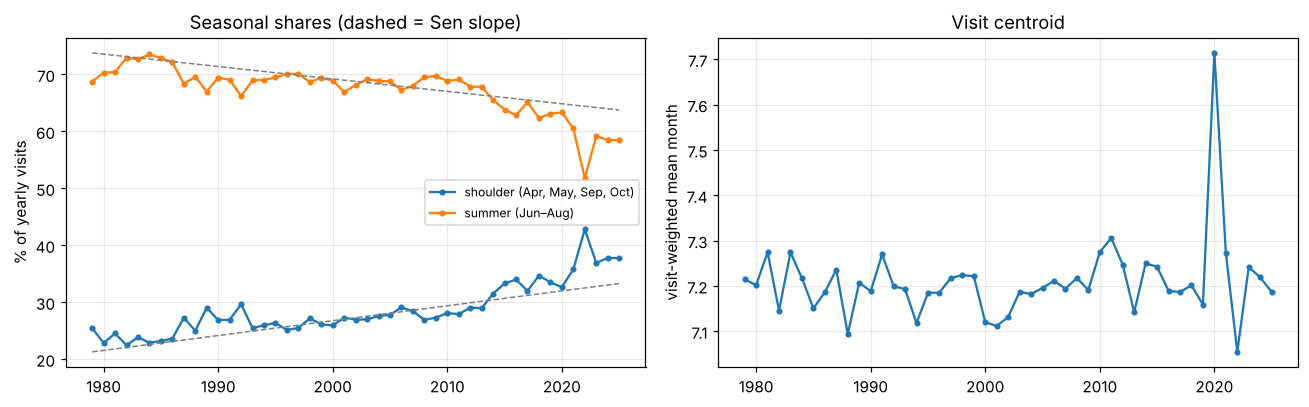

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for s, lab in [(shoulder, "shoulder (Apr, May, Sep, Oct)"), (summer_sh, "summer (Jun–Aug)")]:
    ax[0].plot(s.index, 100 * s, "o-", ms=3, label=lab)
    sl = mk.sens_slope(s.values); xs = np.arange(len(s))
    ax[0].plot(s.index, 100 * (sl.intercept + sl.slope * xs), "--", color="gray", lw=1)
ax[0].set_ylabel("% of yearly visits"); ax[0].legend(fontsize=8); ax[0].set_title("Seasonal shares (dashed = Sen slope)")
ax[1].plot(centroid.index, centroid, "o-", ms=3)
ax[1].set_ylabel("visit-weighted mean month"); ax[1].set_title("Visit centroid")
fig.tight_layout(); fig.savefig(FIG / "q2_shoulder_share.png", dpi=150); plt.show()

In [15]:
d = vv.reset_index().merge(temp, on="Date", how="inner")
d = d[d.Visits > 0].copy()
d["t"] = d.Year - 2000
d["C_count93"], d["C_count13"] = (d.Year >= 1993).astype(int), (d.Year >= 2013).astype(int)
d["shoulder"] = d.Month.isin([4, 5, 9, 10]).astype(int)
base_f = "LogVisits ~ C(Month) + t + C_count93 + C_count13 + D_fire88 + D_covid20 + D_flood22 + D_shutdown"
hac = dict(cov_type="HAC", cov_kwds={"maxlags": 12})
m_a = smf.ols(base_f + " + Temp_mean_C", d).fit(**hac)
m_b = smf.ols(base_f + " + Temp_mean_C + Temp_mean_C:shoulder", d).fit(**hac)
m_c = smf.ols(base_f + " + C(Month):Temp_mean_C", d).fit(**hac)
print(f"n = {int(m_a.nobs)} months, {d.Date.min():%Y-%m} to {d.Date.max():%Y-%m}")
q2_reg = pd.DataFrame([
    dict(model="(a) common slope", term="Temp_mean_C", b=m_a.params.Temp_mean_C, p=m_a.pvalues.Temp_mean_C),
    dict(model="(b) + shoulder interaction", term="Temp_mean_C (non-shoulder)", b=m_b.params.Temp_mean_C, p=m_b.pvalues.Temp_mean_C),
    dict(model="(b) + shoulder interaction", term="extra slope in shoulder months", b=m_b.params["Temp_mean_C:shoulder"], p=m_b.pvalues["Temp_mean_C:shoulder"]),
])
q2_reg["% per °C"] = pct(q2_reg.b)
q2_reg.round(4).to_csv(TAB / "q2_temperature_regression.csv", index=False); q2_reg.round(4)

n = 501 months, 1984-01 to 2025-12


,model,term,b,p,% per °C
0,(a) common slope,Temp_mean_C,0.0296,0.0000,3.0072
1,(b) + shoulder interaction,Temp_mean_C (non-shoulder),0.0145,0.0589,1.4604
2,(b) + shoulder interaction,extra slope in shoulder months,0.0529,0.0000,5.4290


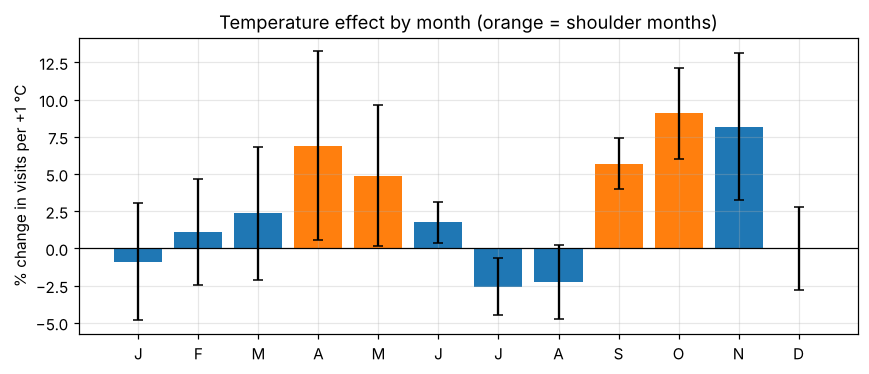

,b,se,p,% per °C
month,,,,
1,-0.009,0.020,0.659,-0.886
2,0.011,0.018,0.548,1.097
3,0.023,0.023,0.307,2.356
4,0.067,0.032,0.038,6.911
5,0.048,0.024,0.049,4.881
6,0.017,0.007,0.013,1.759
7,-0.026,0.010,0.008,-2.582
8,-0.023,0.013,0.072,-2.246
9,0.055,0.009,0.000,5.700


In [16]:
bym = pd.DataFrame({"b": m_c.params.filter(like=":Temp"), "se": m_c.bse.filter(like=":Temp"),
                    "p": m_c.pvalues.filter(like=":Temp")})
bym.index = range(1, 13); bym.index.name = "month"
bym["% per °C"] = pct(bym.b)
bym.round(4).to_csv(TAB / "q2_temperature_slope_by_month.csv")
fig, ax = plt.subplots(figsize=(8, 3.5))
cols = ["C1" if m in (4, 5, 9, 10) else "C0" for m in bym.index]
ax.bar(bym.index, bym["% per °C"], yerr=1.96 * 100 * bym.se, color=cols, capsize=3)
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("% change in visits per +1 °C"); ax.set_title("Temperature effect by month (orange = shoulder months)")
fig.tight_layout(); fig.savefig(FIG / "q2_temperature_by_month.png", dpi=150); plt.show()
bym.round(3)

In [17]:
t_ann = temp.groupby(temp.Date.dt.year).Temp_mean_C.mean().loc[1985:2025]
tt = mk.original_test(t_ann)
print(f"Annual mean temperature trend 1985–2025: {10 * tt.slope:+.2f} °C/decade (Mann–Kendall p = {tt.p:.4f})")
print("Caution: the number of SNOTEL stations varies (1–3) by month, which can shift the mean.")

Annual mean temperature trend 1985–2025: +0.42 °C/decade (Mann–Kendall p = 0.0001)
Caution: the number of SNOTEL stations varies (1–3) by month, which can shift the mean.


### Granger causality and VAR: does temperature *lead* visits?
The regression above shows warmer months have more visitors **in the same month**. Granger
causality asks a different, time-series question: do **past** temperatures help predict visits
beyond what visits' own past already tells us? A VAR (vector autoregression) models both series
jointly, each regressed on lags of both.

* Variables: z₁ = Δ12 log visits (year-on-year growth) and z₂ = Δ12 temperature (this month minus
  the same month last year). Seasonal differencing removes the seasonal cycle from both, so the
  VAR captures only *unusual* warmth and *unusual* visitor growth.
* Sample 1985–2019: the log of 0 visits (Apr 2020) is undefined and COVID would dominate.
  Fire and shutdown dummies, and their 12-month lags (they enter Δ12 twice), are exogenous.
  Two missing temperature months (Mar 1984, Feb 1994) are filled by linear interpolation.
* Tests: Granger temperature → visits (the question), visits → temperature (a **placebo**:
  visitors cannot change the weather, so it should not be significant), and instantaneous
  causality (same-month link, via the correlation of the VAR residuals).

In [18]:
Tm = temp.set_index("Date").Temp_mean_C.asfreq("MS").interpolate(limit=1)
# temperature first: the orthogonalised IRF (Cholesky) then lets weather affect visits in the same
# month, but not the reverse
zv = pd.DataFrame({"temp_change": Tm.diff(12), "visits_growth": y.diff(12)}).loc["1985-01-01":"2019-12-01"]
exo = pd.DataFrame(index=zv.index)
for c_ in ["D_fire88", "D_shutdown"]:
    exo[c_] = v[c_].reindex(zv.index); exo[c_ + "_lag12"] = v[c_].shift(12).reindex(zv.index)
exo = exo.loc[:, exo.sum() > 0]
assert zv.notna().all().all()
stat_rows = []
for c_ in zv:
    stat_rows.append(dict(series=c_, ADF_p=adfuller(zv[c_], autolag="AIC")[1], KPSS_p=kpss(zv[c_], nlags="auto")[1]))
print(f"{len(zv)} months; correlation of the two series: {zv.corr().iloc[0, 1]:.2f}")
pd.DataFrame(stat_rows).round(3)

420 months; correlation of the two series: 0.32


,series,ADF_p,KPSS_p
0,temp_change,0.0,0.1
1,visits_growth,0.0,0.1


In [19]:
var_mod = VAR(zv, exog=exo)
sel = var_mod.select_order(24)
print(sel.summary())
print("Selected lags:", sel.selected_orders)

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -1.338     -1.237*      0.2625      -1.298
1       -1.337      -1.196      0.2626      -1.281
2       -1.329      -1.148      0.2648      -1.257
3       -1.310      -1.089      0.2698      -1.223
4       -1.304      -1.042      0.2715      -1.200
5       -1.286     -0.9847      0.2763      -1.167
6       -1.272     -0.9299      0.2804      -1.136
7       -1.256     -0.8736      0.2849      -1.104
8       -1.244     -0.8215      0.2883      -1.077
9       -1.231     -0.7686      0.2920      -1.048
10      -1.225     -0.7226      0.2938      -1.026
11      -1.216     -0.6732      0.2965      -1.001
12      -1.528     -0.9451      0.2170      -1.297
13      -1.553     -0.9293      0.2118     -1.306*
14      -1.538     -0.8746      0.2150      -1.275
15      -1.545     -0.8410      0.2136      -1.266
16      -1.541     -0.7972     

BIC picks 0 lags — year-on-year growth rates have almost no short-run memory — which leaves
nothing to test. We fit the VAR at 1 and 2 lags and at the HQIC and AIC choices.

A Granger test is only valid if the VAR's residuals are **white noise**: leftover autocorrelation
means the lag length is too short and the F-test's p-values are wrong. So each VAR's residuals are
checked with Ljung–Box (lags 12 and 24, each series) and a joint portmanteau test (36 lags, both
series together). The **main model** is the shortest VAR whose residuals pass Ljung–Box for both
series; the other lag lengths are shown only as a sensitivity check.

In [20]:
from statsmodels.stats.diagnostic import acorr_ljungbox
LAGS = sorted({1, 2, max(sel.selected_orders["hqic"], 1), max(sel.selected_orders["aic"], 1)})
g_rows = []
for L in LAGS:
    rv = var_mod.fit(L)
    g1 = rv.test_causality("visits_growth", ["temp_change"], kind="f")
    g2 = rv.test_causality("temp_change", ["visits_growth"], kind="f")
    ic = rv.test_inst_causality("temp_change")
    lb = {c_: acorr_ljungbox(rv.resid[c_], lags=[12, 24]).lb_pvalue.min() for c_ in zv}   # smaller of lags 12, 24
    wt = rv.test_whiteness(nlags=36, adjusted=True)
    g_rows.append({"lags": L, "temp → visits F": g1.test_statistic, "temp → visits p": g1.pvalue,
                   "visits → temp (placebo) p": g2.pvalue, "instantaneous p": ic.pvalue,
                   "Ljung–Box p, temp resid": lb["temp_change"], "Ljung–Box p, visits resid": lb["visits_growth"],
                   "joint whiteness p (36 lags)": wt.pvalue, "residuals white": min(lb.values()) > 0.05,
                   "stable": rv.is_stable()})
granger_tab = pd.DataFrame(g_rows)
ok = granger_tab[granger_tab["residuals white"]]
L_main = int(ok.lags.min()) if len(ok) else int(granger_tab.lags.max())
main = granger_tab.set_index("lags").loc[L_main]
print(f"Main model: VAR({L_main}) — the shortest lag length whose residuals pass Ljung–Box (lags 12 and 24) "
      f"for both series." if len(ok) else f"No lag length gives white residuals; using the longest, VAR({L_main}).")
granger_tab.round(4).to_csv(TAB / "q2_granger_var.csv", index=False)
granger_tab.round(4)

Main model: VAR(24) — the shortest lag length whose residuals pass Ljung–Box (lags 12 and 24) for both series.


,lags,temp → visits F,temp → visits p,visits → temp (placebo) p,instantaneous p,"Ljung–Box p, temp resid","Ljung–Box p, visits resid",joint whiteness p (36 lags),residuals white,stable
0,1,1.3779,0.2408,0.5120,0.0,0.0000,0.0000,0.0,False,True
1,2,1.4053,0.2459,0.5144,0.0,0.0000,0.0000,0.0,False,True
2,13,0.4600,0.9461,0.7055,0.0,0.0001,0.0209,0.0,False,True
3,24,1.2080,0.2259,0.2463,0.0,0.8144,0.6016,0.0,True,True


### Impulse response
Response of visitor growth to a one-standard-deviation surprise in temperature change
(orthogonalised, temperature ordered first because weather is not affected by visitors), VAR
with the main lag order chosen above (white residuals), 95% bands.

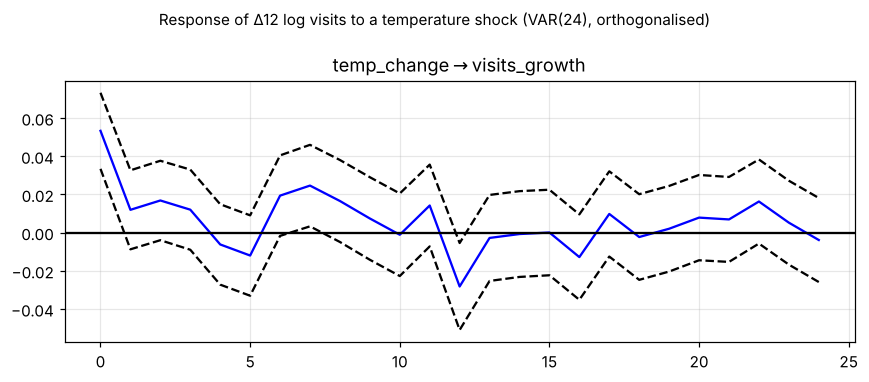

Same-month response: +5.33 log points ×100 of visitor growth per 1 SD of temperature change (1 SD = 2.35 °C); months 1–6: [ 1.2   1.69  1.21 -0.62 -1.2   1.94]


In [21]:
rv = var_mod.fit(L_main)
irf = rv.irf(24)
fig = irf.plot(orth=True, impulse="temp_change", response="visits_growth", figsize=(8, 3.5))
fig.suptitle(f"Response of Δ12 log visits to a temperature shock (VAR({L_main}), orthogonalised)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "q2_var_irf_temp_to_visits.png", dpi=150); plt.show()
oi = irf.orth_irfs[:, 1, 0]          # [horizon, response = visits_growth, impulse = temp_change]
print(f"Same-month response: {100 * oi[0]:+.2f} log points ×100 of visitor growth per 1 SD of temperature change "
      f"(1 SD = {zv.temp_change.std():.2f} °C); months 1–6: {np.round(100 * oi[1:7], 2)}")

**Reading:** shorter VARs leave the yearly (lag 12 and 24) correlation from the Δ12 differencing in
their residuals, so their Granger p-values are not valid. In the main model the residuals of each
series are white noise; the joint whiteness test can still reject because of cross-correlation
between the two residual series at a few lags, so its p-values are approximate. If temperature →
visits is not significant in the main model while the instantaneous test is highly significant,
temperature acts **within the month** — people react to the weather they get (and to the road
openings it allows), not to last month's weather. The placebo direction should be non-significant;
if it were significant, the setup would be suspect.
In the impulse response the dip at month 12 is mechanical: a warm month raises this year's growth
and therefore lowers next year's year-on-year comparison (Δ12) for the same month.

---
# Q3 — How fast does tourism recover from shocks?

### Counterfactual method
For each shock: fit the Q0 SARIMA on log visits up to the month before the shock (with the
dummies for earlier shocks), forecast 36 months, back-transform with exp(μ + σ²/2).
* **Visits lost** = Σ (forecast − actual), (a) from the shock to recovery and (b) over the first
  12 months (comparable across shocks, since recovery dates depend on how wide each band is).
* **Recovery** = first month from which actual visits are back inside the 95% forecast band
  (≥ lower bound) for three consecutive months; recovery time counted from the shock month.
* **Rebound** = Σ (actual − forecast) in the 12 months after recovery (positive = above normal).
* **Worst month** is taken within the first 6 months; **year-2 gap** = actual vs counterfactual in
  months 13–24 after the shock — a fixed window, so it does not depend on the band width.

Caveat: the 95% band widens with the horizon, so "back inside the band" is easier to reach for
the pre-COVID flood baseline (forecasting 2–5 years ahead) than for the others.

| shock | start | note |
|---|---|---|
| 1988 fires | Jul 1988 | fires grew through Aug–Sep; roads closed intermittently |
| COVID | Mar 2020 | park closed Mar 24 – May 18 (South/East), June fully open |
| 2022 flood | Jun 2022 | all entrances closed Jun 13; North/NE closed until Oct |

**Second baseline for the flood.** A model trained up to May 2022 includes the post-COVID
record of 2021 and, because SARIMA (d = D = 1) extrapolates recent growth, expects July 2022–24
at 1.3–1.5M visits — far above any real year (record: 1.08M, Jul 2021). We therefore also
report a **pre-COVID baseline** trained up to Feb 2020, which treats 2019 as "normal".

In [22]:
SHOCKS = {"1988 fires": ("1988-07-01", "1988-07-01"),
          "COVID 2020": ("2020-03-01", "2020-03-01"),
          "2022 flood": ("2022-06-01", "2022-06-01"),
          "2022 flood (pre-COVID baseline)": ("2022-06-01", "2020-03-01")}
SHOCK_D = ["D_fire88", "D_covid20", "D_flood22", "D_shutdown"]

def counterfactual(start, train_until_before, h=36):
    start, cut = pd.Timestamp(start), pd.Timestamp(train_until_before) - pd.DateOffset(months=1)
    Xt = X0[:cut]
    cols = [c for c in Xt.columns if Xt[c].nunique() > 1]
    f = SARIMAX(y[:cut], exog=Xt[cols] if cols else None,
                order=ORDER, seasonal_order=SORDER).fit(disp=False)
    steps = (start.year - cut.year) * 12 + start.month - cut.month + h - 1
    idx_all = pd.date_range(cut + pd.DateOffset(months=1), periods=steps, freq="MS")
    Xf = X0.reindex(idx_all)[cols].copy()
    Xf[[c for c in cols if c in SHOCK_D]] = 0
    pr = f.get_forecast(steps, exog=Xf if cols else None)
    mu, sd = pr.predicted_mean, np.sqrt(pr.var_pred_mean)
    out = pd.DataFrame({"forecast": np.exp(mu + sd ** 2 / 2), "lo95": np.exp(mu - 1.96 * sd),
                        "hi95": np.exp(mu + 1.96 * sd)}, index=idx_all)
    out = out[out.index >= start]
    out["actual"] = v.Visits.reindex(out.index)
    return out.dropna(subset=["actual"])

def summarise(cf, start):
    ok = (cf.actual >= cf.lo95).astype(int)
    run = ok.rolling(3).sum().shift(-2) == 3              # this month and the next two inside
    rec = cf.index[run.fillna(False).values][0] if run.any() else None
    pre = cf[cf.index < rec] if rec is not None else cf
    post = cf[(cf.index >= rec) & (cf.index < rec + pd.DateOffset(months=12))] if rec is not None else cf.iloc[:0]
    first12, year2 = cf.iloc[:12], cf.iloc[12:24]
    win = cf.iloc[:6]                      # shock period: covers every closure (fires Jul–Sep, COVID Mar–Jun, flood Jun–Oct)
    return dict(shock_month=pd.Timestamp(start).strftime("%b %Y"),
                worst_month=win.index[(win.actual / win.forecast).argmin()].strftime("%b %Y"),
                worst_drop_pct=100 * (win.actual / win.forecast - 1).min(),
                visits_lost_to_recovery=(pre.forecast - pre.actual).sum(),
                visits_lost_first_12m=(first12.forecast - first12.actual).sum(),
                recovery_month=rec.strftime("%b %Y") if rec is not None else "not within 36 m",
                recovery_months=((rec.year - pd.Timestamp(start).year) * 12 + rec.month - pd.Timestamp(start).month) if rec is not None else np.nan,
                rebound_12m_after=(post.actual - post.forecast).sum(),
                post_recovery_12m_gap_pct=100 * (post.actual.sum() / post.forecast.sum() - 1) if len(post) else np.nan,
                first_12m_gap_pct=100 * (first12.actual.sum() / first12.forecast.sum() - 1),
                year2_gap_pct=100 * (year2.actual.sum() / year2.forecast.sum() - 1))

cfs, rows = {}, []
for name, (start, train_cut) in SHOCKS.items():
    cfs[name] = counterfactual(start, train_cut)
    rows.append(dict(shock=name, **summarise(cfs[name], start)))
q3_cf = pd.DataFrame(rows).set_index("shock")
q3_cf.round(1).to_csv(TAB / "q3_counterfactual_summary.csv")
pd.concat(cfs, names=["shock", "Date"]).round(0).to_csv(TAB / "q3_counterfactual_paths.csv")
q3_cf.round(1)

,shock_month,worst_month,worst_drop_pct,visits_lost_to_recovery,visits_lost_first_12m,recovery_month,recovery_months,rebound_12m_after,post_recovery_12m_gap_pct,first_12m_gap_pct,year2_gap_pct
shock,,,,,,,,,,,
1988 fires,Jul 1988,Sep 1988,-56.2,665604.4,702153.5,Oct 1988,3,-499361.5,-15.6,-23.8,-19.2
COVID 2020,Mar 2020,Apr 2020,-100.0,416462.9,561384.6,Jun 2020,3,-71857.9,-1.6,-12.8,6.9
2022 flood,Jun 2022,Jul 2022,-55.1,2263468.6,2456723.0,Oct 2022,4,-1600643.1,-26.5,-43.4,-24.9
2022 flood (pre-COVID baseline),Jun 2022,Jul 2022,-48.3,952754.8,1558363.8,Aug 2022,2,-942457.7,-19.5,-32.7,-7.5


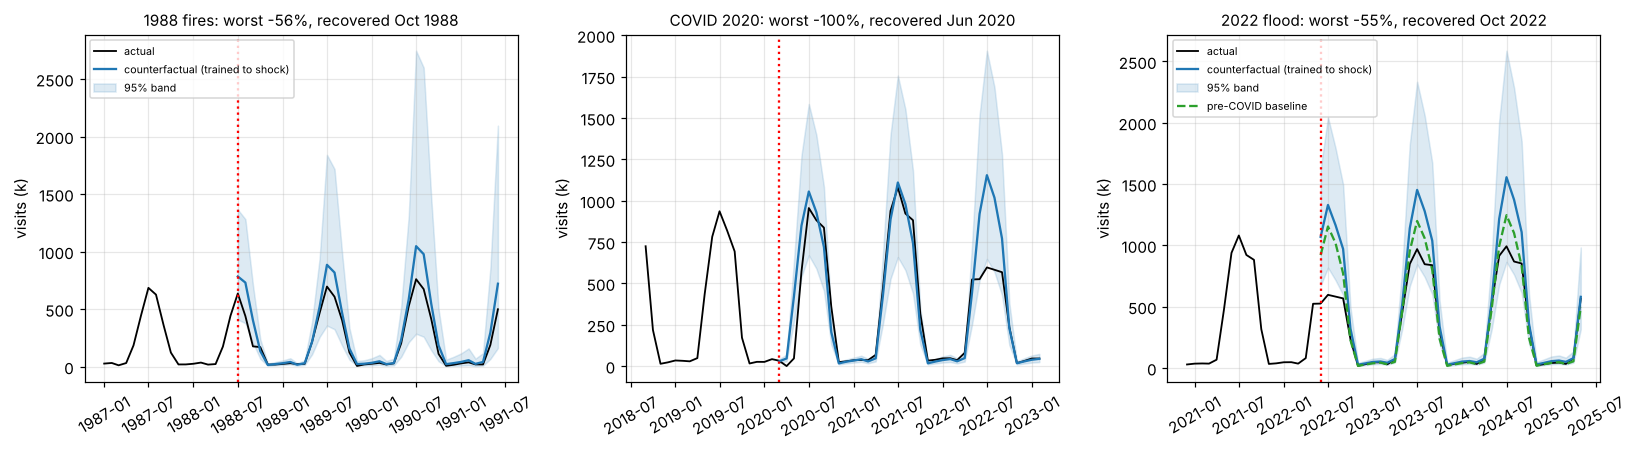

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, ["1988 fires", "COVID 2020", "2022 flood"]):
    cf = cfs[name]
    s, e = cf.index[0] - pd.DateOffset(months=18), cf.index[-1]
    ax.plot(v.Visits[s:e] / 1e3, color="k", lw=1.2, label="actual")
    ax.plot(cf.forecast / 1e3, color="C0", label="counterfactual (trained to shock)")
    ax.fill_between(cf.index, cf.lo95 / 1e3, cf.hi95 / 1e3, color="C0", alpha=0.15, label="95% band")
    if name == "2022 flood":
        alt = cfs["2022 flood (pre-COVID baseline)"]
        ax.plot(alt.forecast / 1e3, color="C2", ls="--", label="pre-COVID baseline")
    ax.axvline(cf.index[0], color="r", ls=":")
    r = q3_cf.loc[name]
    ax.set_title(f"{name}: worst {r.worst_drop_pct:.0f}%, recovered {r.recovery_month}", fontsize=10)
    ax.set_ylabel("visits (k)"); ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=7); axes[2].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "q3_shock_counterfactuals.png", dpi=150); plt.show()

### Did 2021 rebound above normal after COVID?

In [24]:
cv = cfs["COVID 2020"]
yr21 = cv[cv.index.year == 2021]
print(f"2021 actual {yr21.actual.sum():,.0f} vs counterfactual {yr21.forecast.sum():,.0f} "
      f"({100 * (yr21.actual.sum() / yr21.forecast.sum() - 1):+.1f}%); "
      f"months above the 95% band in 2021: {int((yr21.actual > yr21.hi95).sum())}")
print(f"2021 vs 2019 actual: {100 * (v.Visits['2021'].sum() / v.Visits['2019'].sum() - 1):+.1f}%")
print(f"Sep–Dec 2020 actual vs counterfactual: "
      f"{100 * (cv['2020-09':'2020-12'].actual.sum() / cv['2020-09':'2020-12'].forecast.sum() - 1):+.1f}%")

2021 actual 4,860,242 vs counterfactual 4,561,987 (+6.5%); months above the 95% band in 2021: 1
2021 vs 2019 actual: +20.9%
Sep–Dec 2020 actual vs counterfactual: +29.1%


### Robustness: ETS counterfactuals
The SARIMA counterfactuals extrapolate pre-shock **growth** (d = D = 1; see notebook 13, Q0.10),
which can make a shock look bigger and longer-lasting than it was. As a check we repeat the
counterfactuals with **ETS(M,N,M)** — multiplicative error and seasonality, **no trend** — the
specification chosen by AIC in notebook 13. It projects the latest level and seasonal pattern
forward without assuming growth, so it gives a conservative "no growth" baseline.

ETS cannot take dummies or the zero in Apr 2020, so earlier shock months in each training window
(fires, COVID, flood, shutdown months) are replaced by the same month one year earlier.
Prediction intervals are simulated. The same recovery and loss rules are applied. ETS bands are
wider than SARIMA's, so its "back inside the band" dates come earlier; compare the fixed-window
columns (worst month, 12-month loss, year-2 gap) rather than recovery dates.

In [25]:
v_clean = v.Visits.copy()
for d_ in v.index[(v[SHOCK_D].sum(axis=1) > 0)]:
    v_clean[d_] = v_clean[d_ - pd.DateOffset(years=1)]

def counterfactual_ets(start, train_until_before, h=36):
    start, cut = pd.Timestamp(start), pd.Timestamp(train_until_before) - pd.DateOffset(months=1)
    f = ETSModel(v_clean[:cut], error="mul", trend=None, seasonal="mul", seasonal_periods=12).fit(disp=False)
    steps = (start.year - cut.year) * 12 + start.month - cut.month + h - 1
    sf = f.get_prediction(start=cut + pd.DateOffset(months=1), end=cut + pd.DateOffset(months=steps)).summary_frame(alpha=0.05)
    out = pd.DataFrame({"forecast": sf["mean"], "lo95": sf["pi_lower"], "hi95": sf["pi_upper"]})
    out = out[out.index >= start]
    out["actual"] = v.Visits.reindex(out.index)
    return out.dropna(subset=["actual"])

cfs_ets, rows = {}, []
for name, (start, train_cut) in SHOCKS.items():
    cfs_ets[name] = counterfactual_ets(start, train_cut)
    rows.append(dict(shock=name, **summarise(cfs_ets[name], start)))
q3_cf_ets = pd.DataFrame(rows).set_index("shock")
pd.concat(cfs_ets, names=["shock", "Date"]).round(0).to_csv(TAB / "q3_counterfactual_paths_ets.csv")

COLS = ["worst_drop_pct", "visits_lost_first_12m", "first_12m_gap_pct", "recovery_month", "year2_gap_pct"]
q3_rob = pd.concat({"SARIMA": q3_cf[COLS], "ETS": q3_cf_ets[COLS]}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0)
q3_rob = q3_rob[[(c, m) for c in COLS for m in ("SARIMA", "ETS")]]
q3_rob.round(1).to_csv(TAB / "q3_sarima_vs_ets.csv")
q3_rob.round(1)

worst_drop_pct        visits_lost_first_12m  \
                                        SARIMA    ETS                SARIMA   
shock                                                                         
1988 fires                               -56.2  -39.0              702153.5   
COVID 2020                              -100.0 -100.0              561384.6   
2022 flood                               -55.1  -54.6             2456723.0   
2022 flood (pre-COVID baseline)          -48.3  -41.7             1558363.8   

                                           first_12m_gap_pct        \
                                       ETS            SARIMA   ETS   
shock                                                                
1988 fires                        156071.8             -23.8  -6.5   
COVID 2020                        467651.4             -12.8 -10.9   
2022 flood                       2497984.0             -43.4 -43.8   
2022 flood (pre-COVID baseline)  1077328.4             -32.7 -25.2   

                                recovery_month           year2_gap_pct        
                                        SARIMA       ETS        SARIMA   ETS  
shock                                                                         
1988 fires                            Oct 1988  Jul 1988         -19.2  12.2  
COVID 2020                            Jun 2020  Jun 2020           6.9  14.1  
2022 flood                            Oct 2022  Oct 2022         -24.9 -19.7  
2022 flood (pre-COVID baseline)       Aug 2022  Jun 2022          -7.5   6.9

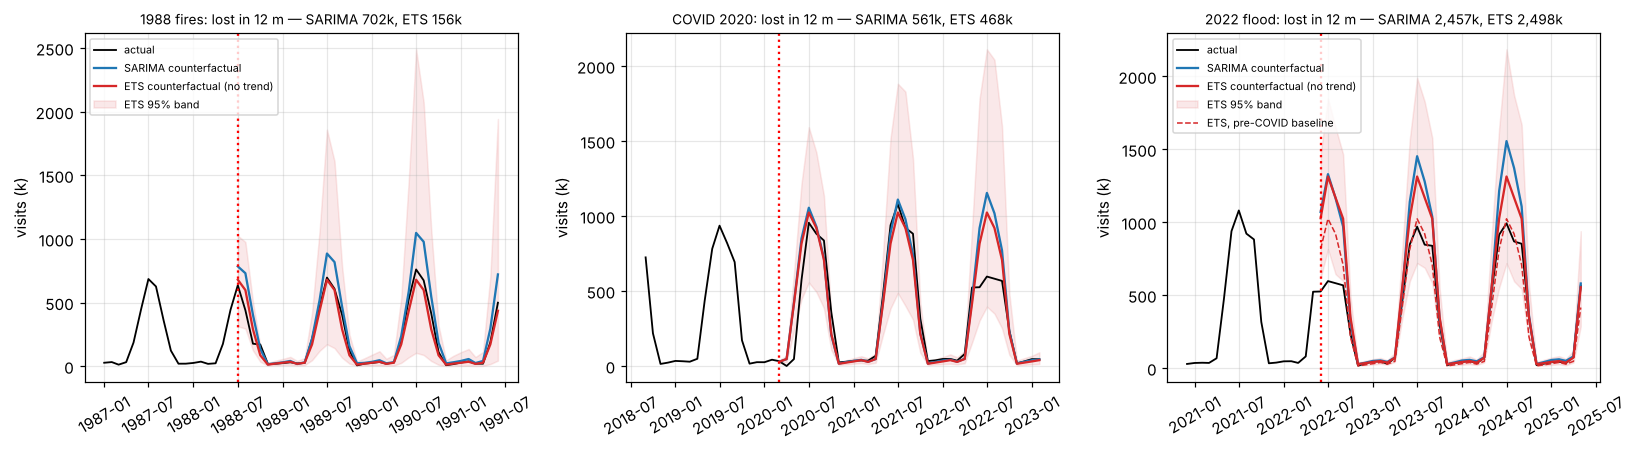

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, ["1988 fires", "COVID 2020", "2022 flood"]):
    cs, ce = cfs[name], cfs_ets[name]
    s_, e_ = cs.index[0] - pd.DateOffset(months=18), cs.index[-1]
    ax.plot(v.Visits[s_:e_] / 1e3, color="k", lw=1.2, label="actual")
    ax.plot(cs.forecast / 1e3, color="C0", label="SARIMA counterfactual")
    ax.plot(ce.forecast / 1e3, color="C3", label="ETS counterfactual (no trend)")
    ax.fill_between(ce.index, ce.lo95 / 1e3, ce.hi95 / 1e3, color="C3", alpha=0.10, label="ETS 95% band")
    if name == "2022 flood":
        ax.plot(cfs_ets["2022 flood (pre-COVID baseline)"].forecast / 1e3, color="C3", ls="--", lw=1,
                label="ETS, pre-COVID baseline")
    ax.axvline(cs.index[0], color="r", ls=":")
    ax.set_title(f"{name}: lost in 12 m — SARIMA {q3_cf.loc[name, 'visits_lost_first_12m'] / 1e3:,.0f}k, "
                 f"ETS {q3_cf_ets.loc[name, 'visits_lost_first_12m'] / 1e3:,.0f}k", fontsize=9)
    ax.set_ylabel("visits (k)"); ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=7); axes[2].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "q3_counterfactuals_sarima_vs_ets.png", dpi=150); plt.show()

**Reading:** where the two methods agree, the result does not depend on whether the pre-shock
growth would have continued; where they disagree, the honest answer is the range between them.
The SARIMA "still below normal a year later" result is the clearest test: if ETS shows visits
back at or above the no-growth baseline, the SARIMA deficit reflects extrapolated growth, not
lost visitors.

### Decay (transfer-function) model
$\log V_t = N_t + \frac{\omega}{1-\delta B} P_t$, with P_t = 1 in the shock's pulse month.
statsmodels has no transfer-function estimator, so δ is profiled: for each δ on a grid
the regressor x_t = Σ_k δ^k P_{t−k} is built, the full-sample Q0 SARIMA is fitted with x_t in
place of that shock's dummy (other shocks keep theirs), and the δ with the highest
log-likelihood is kept. ω is then the immediate effect, half-life = ln 0.5 / ln δ months.

Pulse months: fires **Aug 1988** (first month of large closures; the drop still grew into
September, which a single decaying pulse cannot fit), COVID **May 2020** (April has 0 visits and
no log), flood **Jun 2022**.

In [27]:
PULSE = {"1988 fires": ("1988-08-01", "D_fire88"), "COVID 2020": ("2020-05-01", "D_covid20"),
         "2022 flood": ("2022-06-01", "D_flood22")}
GRID = np.r_[0.0, np.arange(0.1, 0.95, 0.1), 0.95]
drows, profiles = [], {}
for name, (pm, dcol) in PULSE.items():
    P = (v.index == pd.Timestamp(pm)).astype(float)
    ll = []
    for dl in GRID:
        x = np.zeros(len(P))
        for t in range(len(P)):
            x[t] = P[t] + (dl * x[t - 1] if t else 0)
        Xd = X0.drop(columns=dcol).assign(pulse=x)
        if dcol == "D_covid20":       # keep March (partial closure) out of the pulse fit
            Xd = Xd.assign(mar2020=(v.index == "2020-03-01").astype(int))
        f = SARIMAX(y, exog=Xd, order=ORDER, seasonal_order=SORDER).fit(disp=False)
        ll.append((dl, f.llf, f.params.pulse, f.bse.pulse))
    prof = pd.DataFrame(ll, columns=["delta", "llf", "omega", "se"]); profiles[name] = prof
    b = prof.loc[prof.llf.idxmax()]
    ci = prof[prof.llf >= b.llf - 1.92].delta                        # profile-likelihood 95% CI
    drows.append(dict(shock=name, pulse_month=pd.Timestamp(pm).strftime("%b %Y"), omega=b.omega, se=b.se,
                      **{"immediate %": pct(b.omega)}, delta=b.delta, delta_CI=f"{ci.min():.2f}–{ci.max():.2f}",
                      half_life_months=(np.log(0.5) / np.log(b.delta)) if 0 < b.delta < 1 else 0.0))
q3_decay = pd.DataFrame(drows).set_index("shock")
q3_decay.round(3).to_csv(TAB / "q3_decay_models.csv"); q3_decay.round(3)

,pulse_month,omega,se,immediate %,delta,delta_CI,half_life_months
shock,,,,,,,
1988 fires,Aug 1988,-0.347,0.326,-29.320,0.5,0.00–0.95,1.000
COVID 2020,May 2020,-2.274,0.540,-89.714,0.2,0.10–0.30,0.431
2022 flood,Jun 2022,-0.665,0.276,-48.552,0.8,0.60–0.95,3.106


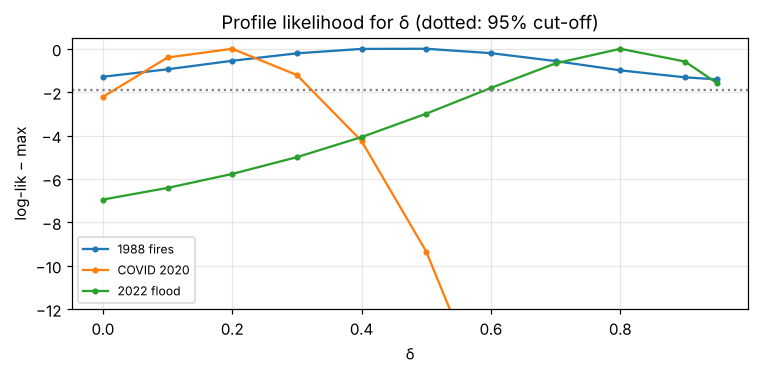

In [28]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, prof in profiles.items():
    ax.plot(prof.delta, prof.llf - prof.llf.max(), "o-", ms=3, label=name)
ax.axhline(-1.92, color="gray", ls=":"); ax.set_xlabel("δ"); ax.set_ylabel("log-lik − max")
ax.set_ylim(-12, 0.5); ax.legend(fontsize=8); ax.set_title("Profile likelihood for δ (dotted: 95% cut-off)")
fig.tight_layout(); fig.savefig(FIG / "q3_delta_profiles.png", dpi=150); plt.show()

### Shock comparison table

In [29]:
q3_table = q3_cf.join(q3_decay[["immediate %", "delta", "delta_CI", "half_life_months"]], how="left")
q3_table = q3_table[["shock_month", "worst_month", "worst_drop_pct", "visits_lost_to_recovery", "visits_lost_first_12m", "recovery_month",
                     "recovery_months", "rebound_12m_after", "first_12m_gap_pct", "year2_gap_pct",
                     "immediate %", "delta", "delta_CI", "half_life_months"]]
q3_table.round(1).to_csv(TAB / "q3_shock_comparison.csv"); q3_table.round(1)

,shock_month,worst_month,worst_drop_pct,visits_lost_to_recovery,visits_lost_first_12m,recovery_month,recovery_months,rebound_12m_after,first_12m_gap_pct,year2_gap_pct,immediate %,delta,delta_CI,half_life_months
shock,,,,,,,,,,,,,,
1988 fires,Jul 1988,Sep 1988,-56.2,665604.4,702153.5,Oct 1988,3,-499361.5,-23.8,-19.2,-29.3,0.5,0.00–0.95,1.0
COVID 2020,Mar 2020,Apr 2020,-100.0,416462.9,561384.6,Jun 2020,3,-71857.9,-12.8,6.9,-89.7,0.2,0.10–0.30,0.4
2022 flood,Jun 2022,Jul 2022,-55.1,2263468.6,2456723.0,Oct 2022,4,-1600643.1,-43.4,-24.9,-48.6,0.8,0.60–0.95,3.1
2022 flood (pre-COVID baseline),Jun 2022,Jul 2022,-48.3,952754.8,1558363.8,Aug 2022,2,-942457.7,-32.7,-7.5,NaN,NaN,NaN,NaN


---
# Q5 — North gate vs other entrances (adapted)

The brief's version (North/NE vs West winter traffic) is not possible with the IRMA traffic
file: in winter the West, South and East gates record **zero wheeled vehicles** (oversnow only,
counted elsewhere) and the Northeast gate is unstaffed. Data start in 1993, giving only
three pre-wolf winters (1994–96). We therefore compare **North-gate winter cars** with
**Highway 191** (regional traffic through the park's west edge, not a wolf destination).

* Difference series: log North − log Hwy 191, winters 1994–2021 (counter change after).
* Intervention: step at winter 1996 (first winter with free-roaming wolves), AR(1) errors.
* Break test: `ruptures` (PELT and binary segmentation, L2 cost) on the difference series.
* A step at 1997 is also shown, but it was chosen **after looking at the data** (the doubling
  is visible in the plot), so its p-value overstates the evidence.

In [30]:
nd["diff"] = nd.ln - nd.lh
q5 = nd.loc[1994:2021].copy()
q5["step96"] = (q5.index >= 1996).astype(int)
q5["step97"] = (q5.index >= 1997).astype(int)
rows = []
for ycol, lab in [("ln", "North gate"), ("diff", "North − Hwy 191")]:
    for k in ["step96", "step97"]:
        for trend in ["c", "ct"]:
            m = ARIMA(q5[ycol], exog=q5[[k]], order=(1, 0, 0), trend=trend).fit()
            rows.append(dict(series=lab, step=k, trend=trend, omega=m.params[k], p=m.pvalues[k],
                             **{"% effect": pct(m.params[k])}))
q5_int = pd.DataFrame(rows); q5_int.round(3).to_csv(TAB / "q5_north_gate_intervention.csv", index=False)
q5_int.round(3)

,series,step,trend,omega,p,% effect
0,North gate,step96,c,0.012,0.926,1.199
1,North gate,step96,ct,-0.119,0.649,-11.206
2,North gate,step97,c,0.671,0.040,95.679
3,North gate,step97,ct,0.669,0.141,95.166
4,North − Hwy 191,step96,c,-0.007,0.962,-0.682
5,North − Hwy 191,step96,ct,-0.124,0.510,-11.645
6,North − Hwy 191,step97,c,0.655,0.000,92.588
7,North − Hwy 191,step97,ct,0.699,0.012,101.102


In [31]:
sig = q5["diff"].values.reshape(-1, 1)
bk = {}
for pen in [0.1, 0.2, 0.5]:
    b = rpt.Pelt(model="l2", min_size=3).fit(sig).predict(pen=pen)
    bk[f"PELT pen={pen}"] = [int(q5.index[i]) for i in b[:-1]]
b1 = rpt.Binseg(model="l2", min_size=3).fit(sig).predict(n_bkps=1)
bk["BinSeg, 1 break"] = [int(q5.index[i]) for i in b1[:-1]]
b2 = rpt.Binseg(model="l2", min_size=3).fit(sig).predict(n_bkps=2)
bk["BinSeg, 2 breaks"] = [int(q5.index[i]) for i in b2[:-1]]
q5_bk = pd.Series({k: ", ".join(map(str, x)) or "none" for k, x in bk.items()}, name="first winter of new segment")
q5_bk.to_csv(TAB / "q5_break_tests.csv"); q5_bk

PELT pen=0.1        1999, 2009
PELT pen=0.2        1999, 2009
PELT pen=0.5              none
BinSeg, 1 break           1999
BinSeg, 2 breaks    1999, 2009
Name: first winter of new segment, dtype: str

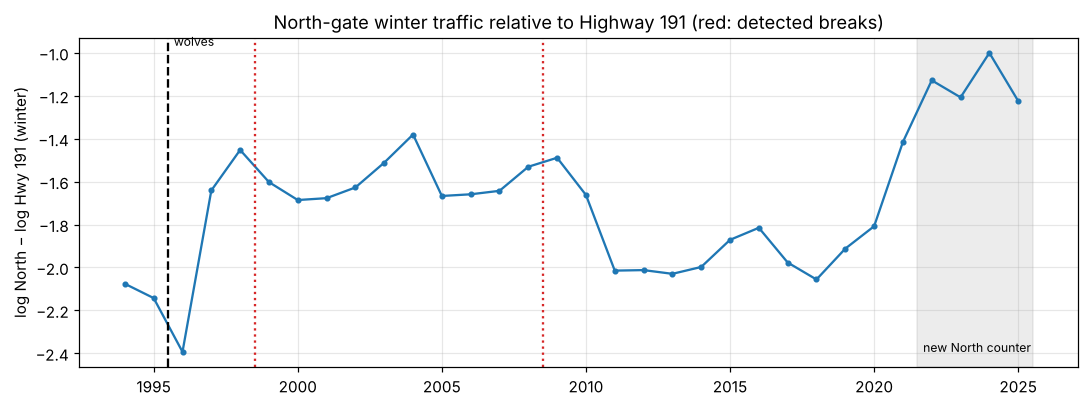

In [32]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(nd.index, nd["diff"], "o-", ms=3)
ax.axvline(1995.5, color="k", ls="--"); ax.text(1995.7, ax.get_ylim()[1] * 0.98, "wolves", fontsize=8, va="top")
ax.axvspan(2021.5, 2025.5, color="gray", alpha=0.15); ax.text(2021.7, nd["diff"].min(), "new North counter", fontsize=8)
for b in bk["BinSeg, 2 breaks"]:
    ax.axvline(b - 0.5, color="C3", ls=":")
ax.set_ylabel("log North − log Hwy 191 (winter)"); ax.set_title("North-gate winter traffic relative to Highway 191 (red: detected breaks)")
fig.tight_layout(); fig.savefig(FIG / "q5_north_vs_hwy191.png", dpi=150); plt.show()

---
## Summary (plain English)

In [33]:
q2s = q2_mk.set_index(["series", "period"])
sh_full = q2s.loc[("shoulder share", "1979–2025")]
cen_full = q2s.loc[("visit centroid (month)", "1979–2025")]
fire, cov, fl, fl2 = (q3_table.loc[k] for k in ["1988 fires", "COVID 2020", "2022 flood", "2022 flood (pre-COVID baseline)"])
q5a = q5_int[(q5_int.series == "North − Hwy 191") & (q5_int.step == "step96") & (q5_int.trend == "c")].iloc[0]
q5b = q5_int[(q5_int.series == "North − Hwy 191") & (q5_int.step == "step97") & (q5_int.trend == "c")].iloc[0]
ets_f, ets_c, ets_fl, ets_fl2 = (q3_cf_ets.loc[k] for k in ["1988 fires", "COVID 2020", "2022 flood", "2022 flood (pre-COVID baseline)"])
lasting_text = ("Once growth is not assumed (ETS), the fires left no lasting dent: the SARIMA\n"
                "    deficit is extrapolated 1980s growth. " if ets_f.year2_gap_pct > -5 > fire.year2_gap_pct else "")
lasting_text += ("For the flood, both models trained to May 2022 show a second-year deficit because both\n"
                 "    treat the record 2021 as normal; with 2019 as normal (pre-COVID baseline) the second year\n"
                 f"    was {ets_fl2.year2_gap_pct:+.0f}% (ETS) to {fl2.year2_gap_pct:+.0f}% (SARIMA), i.e. "
                 + ("roughly back to normal." if max(ets_fl2.year2_gap_pct, fl2.year2_gap_pct) > -5 else "still below normal."))
print(f"""
Q1  {q1_text}

Q2  The season is spreading out. Spring and autumn (Apr, May, Sep, Oct) went from
    {100 * shoulder.loc[1979:1983].mean():.0f}% of yearly visits in 1979–83 to {100 * shoulder.loc[2021:2025].mean():.0f}% in 2021–25
    (Sen slope {100 * sh_full.sen_per_decade:+.1f} percentage points per decade, Mann–Kendall p = {sh_full.p:.1g}),
    while the visit-weighted mean month has not moved (p = {cen_full.p:.2f}): visits are growing at
    both ends of the season, not shifting earlier or later. Warmer months bring more visitors:
    +{q2_reg.iloc[0]['% per °C']:.1f}% per °C overall; +{q2_reg.iloc[1]['% per °C']:.1f}% per °C outside the shoulder months
    and a further +{q2_reg.iloc[2]['% per °C']:.1f}% per °C in them (p = {q2_reg.iloc[2].p:.1g}). In July a warmer month means
    slightly fewer visits ({bym.loc[7, '% per °C']:+.1f}% per °C), consistent with Fisichelli et al. (2015):
    benefits from warming are largest where it is cool. Temperature explains part of the
    shoulder growth; road-opening dates, school calendars and summer crowding also matter and
    are not modelled here.
    The effect is immediate, not lagged. In a VAR of year-on-year visitor growth and temperature
    change (1985–2019), the residuals are white noise only with {L_main} lags (Ljung–Box p ≥ {min(main['Ljung–Box p, temp resid'], main['Ljung–Box p, visits resid']):.2f} for
    both series); shorter VARs leave yearly correlation in the residuals, so their Granger tests are
    not valid. In the {L_main}-lag VAR past temperatures do not Granger-cause visits (p = {main['temp → visits p']:.2f}), while
    the same-month link is very strong (instantaneous causality p = {main['instantaneous p']:.0e}); the placebo
    direction, visits → temperature, is not significant (p = {main['visits → temp (placebo) p']:.2f}). The other lag lengths
    agree (p = {granger_tab['temp → visits p'].min():.2f}–{granger_tab['temp → visits p'].max():.2f}). A joint whiteness test on both residual series still rejects
    (p = {main['joint whiteness p (36 lags)']:.0e}), so the Granger p-values are approximate.
    Visitors respond to the weather of the month they travel in, not to last month's.

Q3  All three shocks were short. By the 95%-band rule visits were back to normal within
    {int(fire.recovery_months)}–{int(fl.recovery_months)} months: fires by {fire.recovery_month}, COVID by {cov.recovery_month}, flood by {fl.recovery_month}.
    Worst months: fires {fire.worst_drop_pct:.0f}% ({fire.worst_month}), COVID {cov.worst_drop_pct:.0f}% ({cov.worst_month}, park
    closed), flood {fl.worst_drop_pct:.0f}% ({fl.worst_month}). Visits lost in the first 12 months: fires
    {fire.visits_lost_first_12m / 1e3:.0f}k, COVID {cov.visits_lost_first_12m / 1e3:.0f}k, flood {fl.visits_lost_first_12m / 1e6:.1f}M (or {fl2.visits_lost_first_12m / 1e6:.1f}M against the
    pre-COVID baseline, which treats 2019 rather than the record 2021 as normal). The flood
    was the costliest because it hit peak season and closed the two northern entrances
    for four months. Decay models agree on the ordering: COVID faded fastest (δ = {cov.delta:.1f},
    half-life {cov.half_life_months:.1f} months), the flood slowest (δ = {fl.delta:.1f}, half-life {fl.half_life_months:.1f} months); the
    fire's δ is not pinned down (95% CI {fire.delta_CI}). COVID was followed by a rebound above
    normal: Sep–Dec 2020 ran {100 * (cv['2020-09':'2020-12'].actual.sum() / cv['2020-09':'2020-12'].forecast.sum() - 1):+.0f}% and 2021 {100 * (yr21.actual.sum() / yr21.forecast.sum() - 1):+.0f}% above the counterfactual (2021 was a record year).
    Robustness (ETS, no-growth baseline): visits lost in the first 12 months are fires
    {ets_f.visits_lost_first_12m / 1e3:.0f}k, COVID {ets_c.visits_lost_first_12m / 1e3:.0f}k, flood {ets_fl.visits_lost_first_12m / 1e6:.1f}M ({ets_fl2.visits_lost_first_12m / 1e6:.1f}M pre-COVID baseline).
    So the loss ranges are: fires {min(fire.visits_lost_first_12m, ets_f.visits_lost_first_12m) / 1e3:.0f}–{max(fire.visits_lost_first_12m, ets_f.visits_lost_first_12m) / 1e3:.0f}k,
    COVID {min(cov.visits_lost_first_12m, ets_c.visits_lost_first_12m) / 1e3:.0f}–{max(cov.visits_lost_first_12m, ets_c.visits_lost_first_12m) / 1e3:.0f}k, flood {min(fl2.visits_lost_first_12m, ets_fl2.visits_lost_first_12m, fl.visits_lost_first_12m, ets_fl.visits_lost_first_12m) / 1e6:.1f}–{max(fl2.visits_lost_first_12m, ets_fl2.visits_lost_first_12m, fl.visits_lost_first_12m, ets_fl.visits_lost_first_12m) / 1e6:.1f}M.
    In the second year after each shock (months 13–24) SARIMA puts visits {fire.year2_gap_pct:+.0f}% (fires),
    {cov.year2_gap_pct:+.0f}% (COVID) and {fl.year2_gap_pct:+.0f}% (flood) against normal; ETS puts them at {ets_f.year2_gap_pct:+.0f}%, {ets_c.year2_gap_pct:+.0f}% and
    {ets_fl.year2_gap_pct:+.0f}% ({ets_fl2.year2_gap_pct:+.0f}% against the pre-COVID baseline). {lasting_text}

Q5  North-gate winter cars relative to Highway 191: a step at the first wolf winter (1996)
    is {q5a['% effect']:+.0f}% (p = {q5a.p:.2f}). Traffic actually doubled one winter later, so a step at 1997
    is {q5b['% effect']:+.0f}% (p {'< 0.001' if q5b.p < 0.001 else f'= {q5b.p:.3f}'}), but that date was picked after seeing the data. The break tests,
    which choose dates blind, put the changes at {q5_bk['BinSeg, 2 breaks']} (a high 1999–2008 plateau
    and a dip in 2009–14 when wolves were fewest). With only three pre-wolf winters
    and no snowmobile counts by gate, this supports but cannot prove a wolf effect on the
    northern range; the brief's North/NE vs West comparison would need IRMA's oversnow counts.
""")


Q1  Did wolves bring tourists? Not in a way that shows up in park-wide visitor counts. Winter visits
(Dec–Mar), which the brief proposed as a proxy for wolf watching, did not rise after wolves were
released. A step at the first wolf winter (1995–96) is -15% (95% CI -50% to
+44%, p = 0.54); adding controls for NPS's 1993 switch to traffic-counter
estimates, the 2004 snowmobile rules and winter severity, a gradual 1995–2000 ramp, a sample
ending in 2002, or modelling winter minus summer all give negative, non-significant estimates
(between -22% and -14%, all p > 0.43).
The monthly SARIMA, which uses all 564 months and is the most precise test, points the same
way: winter months after 1996 are 17% below the pre-wolf pattern (p = 0.04), or
17% below (p = 0.07) with winter severity added. Its 95% interval (-33% to
+1.5%) rules out a park-wide winter increase of more than about 1.5%; the
annual models are much less precise. Summer visits, the control, show no change either
(-8%, p = 0.25). 